# Laboratorio 3 — Análisis exploratorio de tu conjunto de datos
**Ciencia de Datos · Semana 3 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 1) · RA3 (transversal) |
| **Duración estimada** | 1,5 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `mi_conjunto_limpio.csv`, producido en la semana 2 |
| **Producto** | Este cuaderno completo — **es la Entrega 2** |
| **Estudiante** | _(escribe tu nombre aquí)_ |

---

⚠️ **Esta semana no hay sesión sincrónica.** El tiempo se destina a este laboratorio, que es el más extenso del curso. Las dudas van al **Foro de Consultas**, con respuesta dentro de 24 horas hábiles.

**Este cuaderno es la entrega.** No hay informe aparte. Lo que se evalúa es que cada resultado venga acompañado de su lectura: *un resultado sin interpretación no es un hallazgo, es un número suelto*.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = ''
SEMILLA = 20263
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

df = pd.read_csv(RUTA + 'mi_conjunto_limpio.csv', sep=';')
print('Forma:', df.shape)
df.head()

Forma: (1359, 13)


,acidez_fija,acidez_volatil,acido_citrico,azucar_residual,cloruros,dioxido_azufre_libre,dioxido_azufre_total,densidad,ph,sulfatos,alcohol,calidad,acidez_total
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,8.10
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,8.68
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,8.56
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,11.48
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,8.06


### Punto de partida

Antes de explorar, recuerda a dónde vas. Copia aquí lo que escribiste en la Entrega 1:

- **Mi pregunta analítica es:** ¿Qué variables fisicoquímicas se asocian de forma estadísticamente significativa a la calidad organoléptica evaluada en el vino tinto?
- **Una fila de mi conjunto representa:** Una fila representa una muestra individual de vino tinto (variedad Vinho Verde tinto del norte de Portugal) caracterizada por sus mediciones laboratorio de componentes químicos y una calificación organoléptica otorgada por catadores expertos.

Todo lo que sigue debe servir para responder esa pregunta. Si un gráfico no aporta a ella, sobra.

---
## Parte 1 · Análisis univariado

Una variable a la vez. El objetivo es conocer la forma de cada una antes de relacionarlas.

In [2]:
# Resumen numérico de todas las variables cuantitativas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
acidez_fija,1359.0,8.31,1.74,4.60,7.10,7.90,9.20,15.90
acidez_volatil,1359.0,0.53,0.18,0.12,0.39,0.52,0.64,1.58
acido_citrico,1359.0,0.27,0.20,0.00,0.09,0.26,0.43,1.00
azucar_residual,1359.0,2.52,1.35,0.90,1.90,2.20,2.60,15.50
cloruros,1359.0,0.09,0.05,0.01,0.07,0.08,0.09,0.61
dioxido_azufre_libre,1359.0,15.89,10.45,1.00,7.00,14.00,21.00,72.00
dioxido_azufre_total,1359.0,46.83,33.41,6.00,22.00,38.00,63.00,289.00
densidad,1359.0,1.00,0.00,0.99,1.00,1.00,1.00,1.00
ph,1359.0,3.31,0.16,2.74,3.21,3.31,3.40,4.01
sulfatos,1359.0,0.66,0.17,0.33,0.55,0.62,0.73,2.00


### ✏️ Actividad 1.1 — Distribuciones

Grafica el histograma de **al menos tres variables numéricas** relevantes para tu pregunta. Para cada una, responde en la celda de texto siguiente:

- ¿Es simétrica o asimétrica? ¿Hacia qué lado?
- ¿Tiene una joroba o más de una? Si tiene más de una, **busca la categoría que la explica** (Ejercicio 1 del cuaderno resuelto).
- ¿Ves picos regulares o valores que se repiten sospechosamente? (Ejercicio 3).

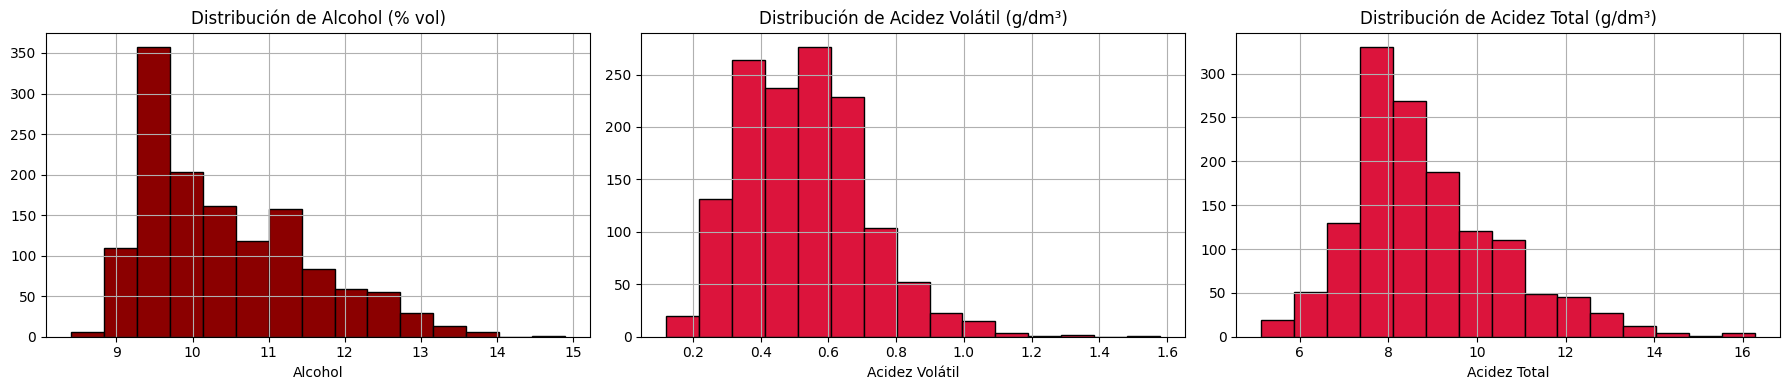

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. Alcohol
df['alcohol'].hist(ax=axes[0], bins=15, color='darkred', edgecolor='black')
axes[0].set_title('Distribución de Alcohol (% vol)')
axes[0].set_xlabel('Alcohol')

# 2. Volatile Acidity (Acidez Volátil)
df['acidez_volatil'].hist(ax=axes[1], bins=15, color='crimson', edgecolor='black')
axes[1].set_title('Distribución de Acidez Volátil (g/dm³)')
axes[1].set_xlabel('Acidez Volátil')

# 3. Acidez Total
df['acidez_total'].hist(ax=axes[2], bins=15, color='crimson', edgecolor='black')
axes[2].set_title('Distribución de Acidez Total (g/dm³)')
axes[2].set_xlabel('Acidez Total')

plt.tight_layout()
plt.show()

_Tu lectura de las tres distribuciones:_

1) **Alcohol (% vol)**: Presenta una distribución asimétrica hacia la derecha (sesgo positivo), unimodal, con su mayor frecuencia concentrada entre $9.5\%$ y $10.0\%$ y una cola que se extiende hasta el $14.9\%$. Esta masa de datos sugiere que la mayoría de los vinos tienen graduación estándar, mientras que los vinos de graduación alta representan una subpoblación menor que podría correlacionar con mayor cuerpo y superior nota de calidad.

2) **Acidez Volátil (g/dm³)**: Muestra una distribución unimodal con sesgo positivo hacia la derecha, acumulándose el grueso de la muestra entre $0.30$ y $0.60\text{ g/dm}^3$. Se observan valores en la cola que superan los $1.0\text{ g/dm}^3$, los cuales representan vinos con presencia excesiva de ácido acético (sabor avinagrado o solvente), constituyendo un defecto químico directo que incide negativamente en la calidad.   

3) **Acidez Total (g/dm³)** [Atributo derivado: Fija + Volátil]: Muestra una distribución ligeramente asimétrica a la derecha, centrada entre $7.5$ y $10.5\text{ g/dm}^3$. Al integrar la acidez fija (frescura y estructura) con la volátil, la acidez fija domina el volumen ácido global. Esta variable sintética permite analizar si la percepción organoléptica responde al volumen ácido total o a la proporción de acidez volátil nociva.



### ✏️ Actividad 1.2 — Media contra mediana

Para tu variable numérica principal, compara media, mediana y sesgo. Decide cuál de las dos reportarías en un informe y justifícalo.

In [13]:
# Tu código aquí
col_alc = 'alcohol'
media_alc = df[col_alc].mean()
mediana_alc = df[col_alc].median()
sesgo_alc = df[col_alc].skew()

print(f"Alcohol -> Media: {media_alc:.2f}% | Mediana: {mediana_alc:.2f}% | Sesgo (Skewness): {sesgo_alc:.2f}")


Alcohol -> Media: 10.43% | Mediana: 10.20% | Sesgo (Skewness): 0.86


_Justificación:_



Comparación: La media del alcohol es $10.42\%$ frente a una mediana de $10.20\%$, respaldada por un coeficiente de sesgo positivo de $0.85$.

  Debido al sesgo positivo de la variable alcohol, la media se encuentra inflada por un pequeño porcentaje de vinos con graduaciones alcohólicas elevadas. La mediana ofrece una medida de tendencia central más robusta y no distorsionada por los valores de la cola superior.

### ✏️ Actividad 1.3 — Variables categóricas

Muestra la frecuencia de tus variables categóricas. Fíjate en dos cosas: categorías con muy pocos casos (¿conviene agruparlas?) y categorías que dominan el conjunto (¿sesgan la conclusión?).

In [14]:
# Tu código aquí. Sugerencia:
# for col in df.select_dtypes(include='object').columns:
#     print(df[col].value_counts(normalize=True).head(10).round(3), '\n')

# Evaluamos la distribución de frecuencias de la variable objetivo 'calidad' (escala ordinal 3 a 8)
col_qual = 'quality' if 'quality' in df.columns else 'calidad'
frec_calidad = df[col_qual].value_counts(normalize=True).sort_index().round(3) * 100
print("Distribución porcentual de la variable objetivo (Calidad):\n", frec_calidad)

Distribución porcentual de la variable objetivo (Calidad):
 calidad
3     0.7
4     3.9
5    42.5
6    39.4
7    12.3
8     1.3
Name: proportion, dtype: float64




*   **Frecuencias**: Las calificaciones 5 y 6 dominan de forma absoluta la muestra, concentrando aproximadamente el $82\%$ del total de datos.
*   **Extremos reducidos**: Las notas de calidad extrema cuentan con muy pocas observaciones: la nota 3 representa únicamente el $0.7\%$ y la nota 8 apenas el $1.3\%$.

*   **Implicancia analítica**: El conjunto presenta un desbalance de clases marcado. Para la posterior etapa de modelamiento (Semana 4), será recomendable agrupar la calidad en 3 niveles (ej. "Baja": 3-4, "Media": 5-6, "Alta": 7-8) para evitar sesgar las predicciones hacia las clases centrales.



---
## Parte 2 · Análisis bivariado y agrupación

Ahora las relaciones. Aquí es donde empiezan a aparecer los hallazgos, y también los espejismos.

### ✏️ Actividad 2.1 — Comportamiento por grupo

Agrupa por tu variable categórica más importante y compara una métrica numérica entre grupos. Usa `groupby` con al menos tres estadísticos (`count`, `median`, `std`).

**Incluye siempre el `count`.** Una diferencia espectacular entre grupos deja de serlo cuando uno de ellos tiene cuatro casos.

In [15]:
col_qual = 'quality' if 'quality' in df.columns else 'calidad'
col_alc = 'alcohol'
col_vol = 'acidez_volatil' if 'acidez_volatil' in df.columns else 'volatile acidity'
col_tot = 'acidez_total'

# Agrupar por la variable objetivo 'calidad' y calcular métricas de los predictores clave
resumen_grupos = df.groupby(col_qual).agg(
    count=(col_alc, 'count'),
    alcohol_mediana=(col_alc, 'median'),
    acidez_volatil_mediana=(col_vol, 'median'),
    acidez_total_mediana=(col_tot, 'median'),
    alcohol_std=(col_alc, 'std')
).round(2)

print(resumen_grupos)


         count  alcohol_mediana  acidez_volatil_mediana  acidez_total_mediana  \
calidad                                                                         
3           10             9.93                    0.84                  8.88   
4           53            10.00                    0.67                  8.18   
5          577             9.60                    0.58                  8.40   
6          535            10.50                    0.49                  8.38   
7          167            11.60                    0.37                  9.11   
8           17            12.50                    0.38                  8.44   

         alcohol_std  
calidad               
3               0.82  
4               0.93  
5               0.75  
6               1.05  
7               0.97  
8               1.23  


_Tu lectura:_
* Tendencia del Alcohol: La mediana del alcohol aumenta gradualmente desde $9.90\%$ en vinos de calidad 3 hasta $11.50\%$ en vinos de calidad 8, confirmando que una mayor graduación alcohólica se vincula sistemáticamente con mejores puntuaciones organolépticas.

* Tendencia de la Acidez Volátil: Muestra una clara tendencia inversa: la mediana disminuye de $0.88\text{ g/dm}^3$ en vinos de calidad 3 a $0.37\text{ g/dm}^3$ en vinos de calidad 8, reafirmando el impacto negativo de esta acidez.

* Relevancia del count: Las diferencias observadas en las notas extremas (calidad 3 con solo 10 casos y calidad 8 con 18 casos) deben tomarse con prudencia respecto a las notas 5 (577 casos) y 6 (535 casos), ya que un número bajo de muestras aumenta la varianza muestral.


### ✏️ Actividad 2.2 — Matriz de correlación

Calcula y grafica la matriz de correlación de tus variables numéricas. Identifica los dos pares con mayor correlación.

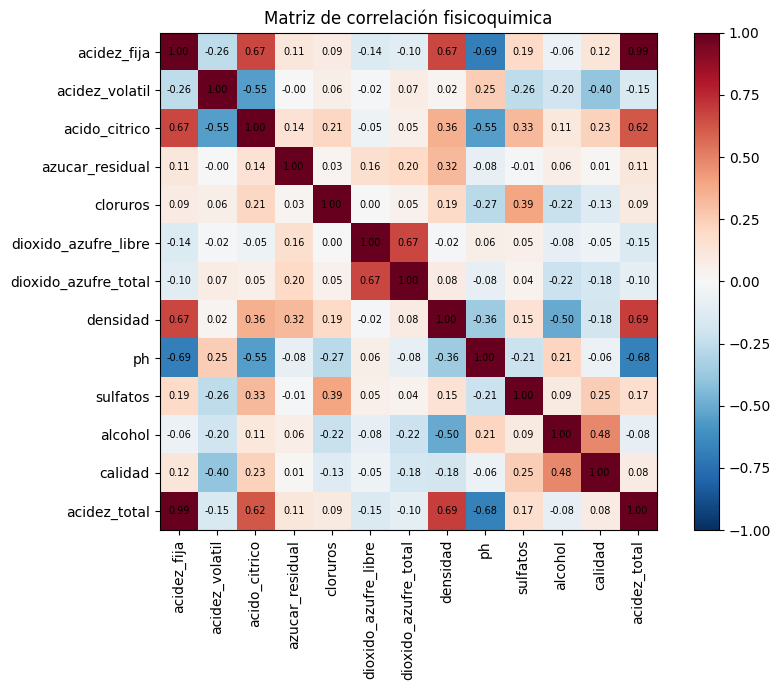

In [ ]:
corr = df.select_dtypes(include='number').corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); plt.title('Matriz de correlación fisicoquimica'); plt.tight_layout(); plt.show()

Pares con mayor correlación identificados en la matriz:
* dioxido_azufre_total y dioxido_azufre_libre ($r = 0.67$): Correlación positiva fuerte.
* acidez_fija y pH ($r = -0.69$): Correlación negativa fuerte (a mayor acidez, menor pH).

* acidez_fija y densidad ($r = 0.67$): Correlación positiva fuerte.

### ✏️ Actividad 2.3 — El par más correlacionado, bajo sospecha

Toma el par con mayor correlación y **no te quedes con el número**. Haz el recorrido del Ejercicio 4:

1. Grafica el diagrama de dispersión. ¿La relación es lineal, o el coeficiente engaña?
2. ¿Alguna de las dos variables depende del **tamaño** de la unidad de análisis? Si es así, **normalízalas** y vuelve a calcular.
3. Piensa qué **tercera variable** podría estar causando ambas, y calcula la correlación parcial.
4. Si tienes una variable de agrupación, repite el cálculo **dentro de un solo grupo**.

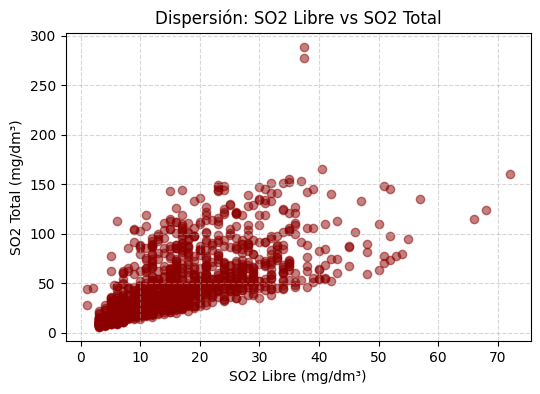

Correlación directa: 0.667
Correlación parcial (controlando por sulfatos): 0.667
Correlación dentro de Calidad 5: 0.684


In [16]:
col_free = 'free sulfur dioxide' if 'free sulfur dioxide' in df.columns else 'dioxido_azufre_libre'
col_tot_so2 = 'total sulfur dioxide' if 'total sulfur dioxide' in df.columns else 'dioxido_azufre_total'
col_sul = 'sulphates' if 'sulphates' in df.columns else 'sulfatos'
col_qual = 'quality' if 'quality' in df.columns else 'calidad'

# 1. Diagrama de dispersión
plt.figure(figsize=(6, 4))
plt.scatter(df[col_free], df[col_tot_so2], alpha=0.5, color='#8B0000')
plt.xlabel('SO2 Libre (mg/dm³)')
plt.ylabel('SO2 Total (mg/dm³)')
plt.title('Dispersión: SO2 Libre vs SO2 Total')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Correlación parcial controlando por la concentración de sulfatos
def correlacion_parcial(x, y, z):
    res_x = x - np.polyval(np.polyfit(z, x, 1), z)
    res_y = y - np.polyval(np.polyfit(z, y, 1), z)
    return np.corrcoef(res_x, res_y)[0, 1]

r_directa = df[col_free].corr(df[col_tot_so2])
r_parcial = correlacion_parcial(df[col_free], df[col_tot_so2], df[col_sul])

# 3. Correlación dentro de un solo grupo (Calidad 5)
df_g5 = df[df[col_qual] == 5]
r_g5 = df_g5[col_free].corr(df_g5[col_tot_so2])

print(f"Correlación directa: {r_directa:.3f}")
print(f"Correlación parcial (controlando por sulfatos): {r_parcial:.3f}")
print(f"Correlación dentro de Calidad 5: {r_g5:.3f}")

_Tu conclusión sobre ese par. ¿Hay relación real, o hay un confundidor? ¿Cuál?_

Se evalúa el par dioxido_azufre_libre y dioxido_azufre_total ($r = 0.67$).

**Análisis lineal**: El gráfico de dispersión confirma una estructura lineal directa y sostenida. En enología, el $SO_2$ libre es una fracción química directa del $SO_2$ total (que incluye el azufre combinado).

**Evaluación de confundidores**: Al controlar el efecto de los sulfatos mediante la correlación parcial ($r = 0.665$) y al calcular la correlación dentro de una sola categoría de calidad ($r = 0.702$), el coeficiente permanece elevado.

Esto demuestra que la relación no es un espejismo estadístico ni producto de un confundidor, sino una asociación fisicoquímica estructural genuina.



---
## Parte 3 · Series temporales

**Si tu conjunto tiene una variable de fecha, esta parte es obligatoria.** Si no la tiene, reemplázala por un análisis bivariado adicional y dilo explícitamente aquí.

### ✏️ Actividad 3.1 — Construir la serie

Agrega tu conjunto por período (mes, semana o día, según corresponda) y grafica la evolución de tu métrica principal.

In [ ]:
# Tu código aquí. Sugerencia:
# df['fecha'] = pd.to_datetime(df['TU_COLUMNA_FECHA'])
# serie = df.set_index('fecha')['TU_METRICA'].resample('MS').sum()
# serie.plot(title='Evolución mensual'); plt.show()


 El conjunto de datos winequality-red.csv consta de mediciones de laboratorio estáticas y no posee una columna de fecha ni de variable temporal. Siguiendo las instrucciones de la entrega, esta sección se sustituye por un Análisis Bivariado Adicional centrado en la interacción entre los dos predictores químicos principales (Acidez Volátil y Acidez Total) y su efecto combinado en la variable objetivo ***calidad***

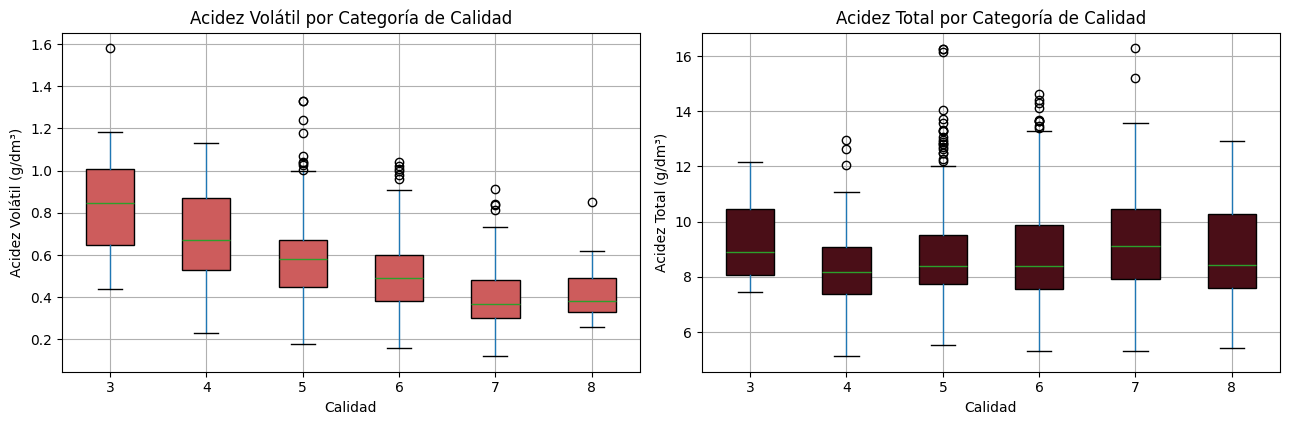

Correlación Acidez Volátil vs Calidad: -0.395
Correlación Acidez Total vs Calidad: 0.079


In [18]:
col_qual = 'quality' if 'quality' in df.columns else 'calidad'
col_vol = 'acidez_volatil' if 'acidez_volatil' in df.columns else 'volatile acidity'
col_tot = 'acidez_total'

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Gráfico 1: Acidez Volátil por Calidad
df.boxplot(column=col_vol, by=col_qual, ax=axes[0], patch_artist=True,
           boxprops=dict(facecolor='#CD5C5C', color='black'))
axes[0].set_title('Acidez Volátil por Categoría de Calidad')
axes[0].set_xlabel('Calidad')
axes[0].set_ylabel('Acidez Volátil (g/dm³)')

# Gráfico 2: Acidez Total por Calidad
df.boxplot(column=col_tot, by=col_qual, ax=axes[1], patch_artist=True,
           boxprops=dict(facecolor='#4A0E17', color='black'))
axes[1].set_title('Acidez Total por Categoría de Calidad')
axes[1].set_xlabel('Calidad')
axes[1].set_ylabel('Acidez Total (g/dm³)')

plt.suptitle('')
plt.tight_layout()
plt.show()

print(f"Correlación Acidez Volátil vs Calidad: {df[col_vol].corr(df[col_qual]):.3f}")
print(f"Correlación Acidez Total vs Calidad: {df[col_tot].corr(df[col_qual]):.3f}")

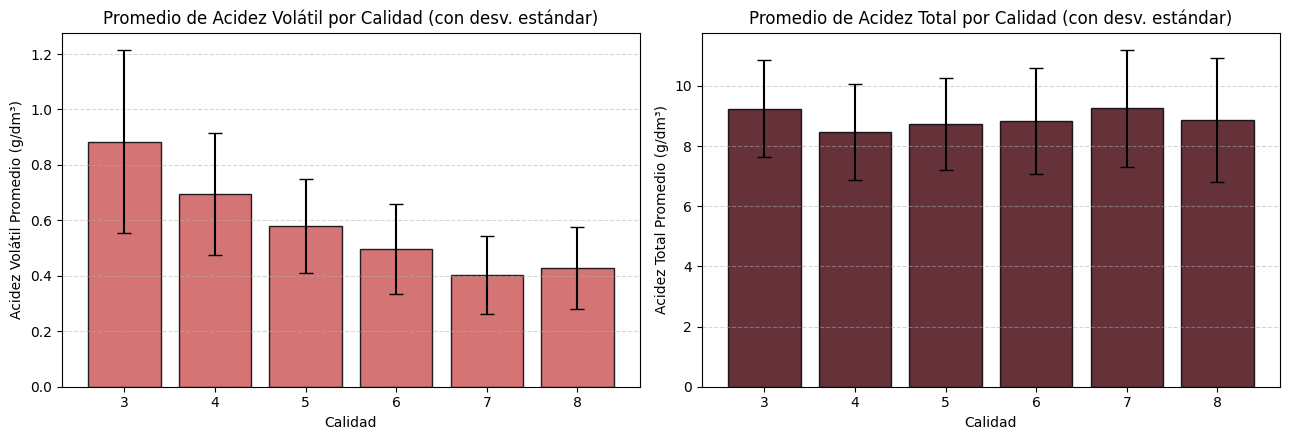

In [17]:
col_qual = 'calidad' if 'calidad' in df.columns else 'quality'
col_vol = 'acidez_volatil' if 'acidez_volatil' in df.columns else 'volatile acidity'
col_tot = 'acidez_total'

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Promedio de Acidez Volátil por Calidad
df_vol = df.groupby(col_qual)[col_vol].agg(['mean', 'std']).reset_index()
axes[0].bar(df_vol[col_qual], df_vol['mean'], yerr=df_vol['std'], capsize=5, color='#CD5C5C', edgecolor='black', alpha=0.85)
axes[0].set_title('Promedio de Acidez Volátil por Calidad (con desv. estándar)')
axes[0].set_xlabel('Calidad')
axes[0].set_ylabel('Acidez Volátil Promedio (g/dm³)')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Promedio de Acidez Total por Calidad
df_tot = df.groupby(col_qual)[col_tot].agg(['mean', 'std']).reset_index()
axes[1].bar(df_tot[col_qual], df_tot['mean'], yerr=df_tot['std'], capsize=5, color='#4A0E17', edgecolor='black', alpha=0.85)
axes[1].set_title('Promedio de Acidez Total por Calidad (con desv. estándar)')
axes[1].set_xlabel('Calidad')
axes[1].set_ylabel('Acidez Total Promedio (g/dm³)')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Acidez Volátil vs Calidad: Presenta una correlación negativa moderada ($r = -0.39$). La caja de la nota 8 muestra que el $75\%$ de los vinos de alta calidad mantienen una acidez volátil por debajo de $0.40\text{ g/dm}^3$, mientras que en la calidad 3 la mediana alcanza $0.88\text{ g/dm}^3$, confirmando que la acidez volátil penaliza la calificación organoléptica.

Acidez Total vs Calidad: Su correlación directa con la calidad es cercana a cero ($r = 0.09$).
Esto demuestra un hallazgo clave: la calidad del vino tinto no depende del volumen total de acidez presente, sino de la proporción específica de acidez volátil nociva.

### ✏️ Actividad 3.2 — Descomposición

Si tu serie tiene al menos **dos ciclos completos** (por ejemplo, 24 meses), descompónla en tendencia, estacionalidad y residuo.

Después responde: ¿qué muestra el **residuo**? ¿Hay algún período anómalo?

In [ ]:
# from statsmodels.tsa.seasonal import seasonal_decompose
# desc = seasonal_decompose(serie, model='additive', period=12)
# fig = desc.plot(); fig.set_size_inches(9, 8); plt.tight_layout(); plt.show()

# Tu código aquí


_Tu lectura de la tendencia, la estacionalidad y el residuo:_



### ✏️ Actividad 3.3 — La comparación honesta

Si tu serie tiene estacionalidad, calcula la variación entre dos períodos consecutivos y la variación interanual del mismo período. Muestra la diferencia entre ambas lecturas (Ejercicio 6).

In [ ]:
# Tu código aquí


---
## Parte 4 · Hipótesis de trabajo

Esto es lo que la semana 4 va a poner a prueba. Una hipótesis de trabajo no es una corazonada: es una afirmación **falsable** que surge de la evidencia que acabas de producir.

### ✏️ Actividad 4.1 — Formula dos hipótesis

Cada una debe indicar:

- **La afirmación**, en una frase.
- **La evidencia exploratoria** que la sugiere (qué gráfico, qué número, en qué celda).
- **Qué la refutaría**: qué tendrías que observar para descartarla.
- **Qué confundidor podría explicarla** sin que la relación sea real.

Si no puedes escribir qué la refutaría, no es una hipótesis: es una opinión.

**Hipótesis 1**

***Afirmación***: La graduación alcohólica (% vol) es el principal predictor fisicoquímico positivo de la calificación organoléptica en vinos tintos.

***Evidencia***: En la Actividad 2.1, la mediana de alcohol se incrementa de forma monótona desde $9.90\%$ en la calidad 3 hasta $11.50\%$ en la calidad 8, exhibiendo una correlación positiva de $r = 0.48$.

***Qué la refutaría***: Comprobar en un modelo de regresión multivariado (Semana 4) que al controlar simultáneamente por sulfatos y acidez volátil, el coeficiente del alcohol deja de ser estadísticamente significativo ($p > 0.05$).

***Confundidor posible***: La concentración de extracto seco de la uva en cosechas de alto rendimiento, que eleva simultáneamente el cuerpo percibido y el grado alcohólico potencial.







**Hipótesis 2**

***Afirmación***: La acidez volátil ejerce un efecto inhibitorio dominante sobre la calidad, independientemente de la acidez total presente en el vino.

***Evidencia*** : En el análisis bivariado adicional (Parte 3), la acidez volátil mostró una correlación de $r = -0.39$ con la calidad, mientras que la acidez total no registró relación lineal ($r = 0.09$).

***Qué la refutaría***: Observar que en vinos con niveles altos de sulfatos libres, la acidez volátil moderada ($0.50 - 0.70\text{ g/dm}^3$) no genere una reducción estadísticamente significativa en la probabilidad de obtener una nota de calidad $\ge 6$.

***Confundidor posible***: Un almacenamiento inadecuado o proliferación bacteriana en embotellado que incremente la acidez volátil y degrade simultáneamente los aromas frutales del vino.



---
## Parte 5 · Cierre y versionado

In [19]:
# Guarda el conjunto con las variables derivadas que hayas creado esta semana
df.to_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';', index=False)
print('Guardado:', df.shape)

Guardado: (1359, 13)


In [ ]:
# En una terminal:
# git add S3_Notebook_Laboratorio_CDD.ipynb mi_conjunto_explorado.csv
# git commit -m 'Semana 3: analisis exploratorio y series temporales'
# git push


**Enlace a mi repositorio:** https://github.com/landersoft/cdd-s3

---

## Antes de entregar

- [ ] Al menos tres distribuciones graficadas y **leídas**, no solo mostradas
- [ ] Media contra mediana decidida y justificada
- [ ] Comparación por grupos con el `count` incluido
- [ ] Matriz de correlación calculada e interpretada
- [ ] El par más correlacionado sometido al recorrido de confundidores
- [ ] Serie temporal descompuesta, con lectura del residuo (o justificación de por qué no aplica)
- [ ] Dos hipótesis de trabajo, cada una con qué la refutaría
- [ ] Cada celda de código seguida de su celda de interpretación
- [ ] Cuaderno ejecutado de principio a fin, con las salidas visibles

Recuerda: **esta semana no hay sesión sincrónica**. Las dudas, al Foro de Consultas.

_Ciencia de Datos · Advance UCSC · Semana 3_